In [1]:
import joblib
import pandas as pd

# Load trained models
lr_pipeline = joblib.load(
    "../models/logistic_regression_pipeline.pkl"
)

best_rf_model = joblib.load(
    "../models/tuned_random_forest.pkl"
)

# Load selected thresholds
model_thresholds = joblib.load(
    "../models/model_thresholds.pkl"
)

lr_threshold = model_thresholds["logistic_regression"]
rf_threshold = model_thresholds["random_forest"]

print("Models loaded successfully!")
print("Logistic Regression threshold:", lr_threshold)
print("Random Forest threshold:", rf_threshold)

Models loaded successfully!
Logistic Regression threshold: 0.35
Random Forest threshold: 0.3


In [2]:
df = pd.read_csv(
    "../dataset/Telco-Customer-Churn-Feature-Engineered.csv"
)

X = df.drop(columns=["Churn"])

print("Number of input features:", X.shape[1])
print("\nFeature columns:")
print(X.columns.tolist())

Number of input features: 34

Feature columns:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'TotalServices', 'TenureGroup_Medium', 'TenureGroup_Long-term', 'TenureGroup_Loyal']


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the feature-engineered dataset
df = pd.read_csv("../dataset/Telco-Customer-Churn-Feature-Engineered.csv")

# Separate input features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Recreate the same train-test split used in Notebook 06
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (5616, 34)
Testing data shape: (1405, 34)


In [5]:
# Select the first customer from test data
new_customer = X_test.iloc[[0]].copy()

# Get the actual churn status
actual_churn = y_test.iloc[0]

print("Customer features:")
display(new_customer)

print("Actual churn:", actual_churn)

Customer features:


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,gender_Male,MultipleLines_No phone service,...,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TotalServices,TenureGroup_Medium,TenureGroup_Long-term,TenureGroup_Loyal
5615,1,1,0,7,1,1,74.85,485.25,1,0,...,0,0,0,0,1,0,3,0,0,0


Actual churn: 0


In [6]:
# Logistic Regression prediction
lr_probability = lr_pipeline.predict_proba(new_customer)[0, 1]
lr_prediction = int(lr_probability >= lr_threshold)

# Random Forest prediction
rf_probability = best_rf_model.predict_proba(new_customer)[0, 1]
rf_prediction = int(rf_probability >= rf_threshold)

print("Actual Churn:", actual_churn)

print("\nLogistic Regression:")
print("Churn Probability:", round(lr_probability, 4))
print("Prediction:", "Churn" if lr_prediction == 1 else "No Churn")

print("\nRandom Forest:")
print("Churn Probability:", round(rf_probability, 4))
print("Prediction:", "Churn" if rf_prediction == 1 else "No Churn")

Actual Churn: 0

Logistic Regression:
Churn Probability: 0.784
Prediction: Churn

Random Forest:
Churn Probability: 0.6688
Prediction: Churn


In [8]:
# Display all variables containing 'model'
[name for name in globals() if 'model' in name.lower()]

['best_rf_model', 'model_thresholds']

In [10]:
import os

print("Current Directory:")
print(os.getcwd())

print("\nFiles in Current Directory:")
print(os.listdir())

Current Directory:
/home/bharath/Downloads/Customer-Churn-Prediction/notebooks

Files in Current Directory:
['03_Data_Cleaning.ipynb', '07_Model_Evaluation.ipynb', '04_Exploratory_Data_Analysis.ipynb', '01_Data_Collection.ipynb', '05_Feature_Engineering.ipynb', '06_Model_Training.ipynb', '02_Data_Understanding.ipynb']


In [11]:
import os

project_path = os.path.expanduser(
    "~/Downloads/Customer-Churn-Prediction"
)

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.endswith(".pkl"):
            print(os.path.join(root, file))

/home/bharath/Downloads/Customer-Churn-Prediction/models/logistic_regression_pipeline.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/models/model_thresholds.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/models/tuned_random_forest.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packages/numpy/_core/tests/data/astype_copy.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.10.0_pickle_py33_np18.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.9.2_pickle_py34_np19.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.9.2_pickle_py35_np19.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.10.0_pickle_py27_np17.pkl
/home/bharath/Downloads/Customer-Churn-Prediction/.venv/lib/python3.12/site-packa

In [13]:
import joblib

# Load Logistic Regression pipeline
logistic_model = joblib.load(
    "/home/bharath/Downloads/Customer-Churn-Prediction/models/logistic_regression_pipeline.pkl"
)

# Load tuned Random Forest
random_forest_model = joblib.load(
    "/home/bharath/Downloads/Customer-Churn-Prediction/models/tuned_random_forest.pkl"
)

# Load optimized thresholds
model_thresholds = joblib.load(
    "/home/bharath/Downloads/Customer-Churn-Prediction/models/model_thresholds.pkl"
)

print("All models and thresholds loaded successfully!")
print("\nThresholds:")
print(model_thresholds)

All models and thresholds loaded successfully!

Thresholds:
{'logistic_regression': 0.35, 'random_forest': 0.3}


In [14]:
# Logistic Regression
lr_probability = logistic_model.predict_proba(new_customer)[0][1]

# Random Forest
rf_probability = random_forest_model.predict_proba(new_customer)[0][1]

print("Actual Churn:", actual_churn)

print("\nLogistic Regression:")
print("Churn Probability:", round(lr_probability, 4))

print("\nRandom Forest:")
print("Churn Probability:", round(rf_probability, 4))

Actual Churn: 0

Logistic Regression:
Churn Probability: 0.784

Random Forest:
Churn Probability: 0.6688


In [15]:
print("Optimized Thresholds:")
print(model_thresholds)

Optimized Thresholds:
{'logistic_regression': 0.35, 'random_forest': 0.3}


In [16]:
# Get optimized thresholds
lr_threshold = model_thresholds['logistic_regression']
rf_threshold = model_thresholds['random_forest']

# Apply thresholds
lr_prediction = int(lr_probability >= lr_threshold)
rf_prediction = int(rf_probability >= rf_threshold)

print("Actual Churn:", actual_churn)

print("\nLogistic Regression:")
print("Probability:", round(lr_probability, 4))
print("Threshold:", lr_threshold)
print("Prediction:", lr_prediction)

print("\nRandom Forest:")
print("Probability:", round(rf_probability, 4))
print("Threshold:", rf_threshold)
print("Prediction:", rf_prediction)

Actual Churn: 0

Logistic Regression:
Probability: 0.784
Threshold: 0.35
Prediction: 1

Random Forest:
Probability: 0.6688
Threshold: 0.3
Prediction: 1


In [17]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Actual values
y_actual = y_test

# Predicted probabilities
lr_probs = logistic_model.predict_proba(X_test)[:, 1]
rf_probs = random_forest_model.predict_proba(X_test)[:, 1]

# Thresholds
lr_threshold = model_thresholds['logistic_regression']
rf_threshold = model_thresholds['random_forest']

# Predictions using default threshold
lr_default = (lr_probs >= 0.5).astype(int)
rf_default = (rf_probs >= 0.5).astype(int)

# Predictions using optimized threshold
lr_optimized = (lr_probs >= lr_threshold).astype(int)
rf_optimized = (rf_probs >= rf_threshold).astype(int)

print("Predictions generated successfully!")


Predictions generated successfully!


In [18]:
results = []

models = {
    "Logistic Regression (Default)": lr_default,
    "Logistic Regression (Optimized)": lr_optimized,
    "Random Forest (Default)": rf_default,
    "Random Forest (Optimized)": rf_optimized
}

for name, predictions in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_actual, predictions),
        "Precision": precision_score(y_actual, predictions, zero_division=0),
        "Recall": recall_score(y_actual, predictions, zero_division=0),
        "F1 Score": f1_score(y_actual, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (Default),0.8028,0.6727,0.4973,0.5719
1,Logistic Regression (Optimized),0.7715,0.5563,0.6774,0.6109
2,Random Forest (Default),0.7936,0.6507,0.4758,0.5497
3,Random Forest (Optimized),0.7544,0.5258,0.7392,0.6145


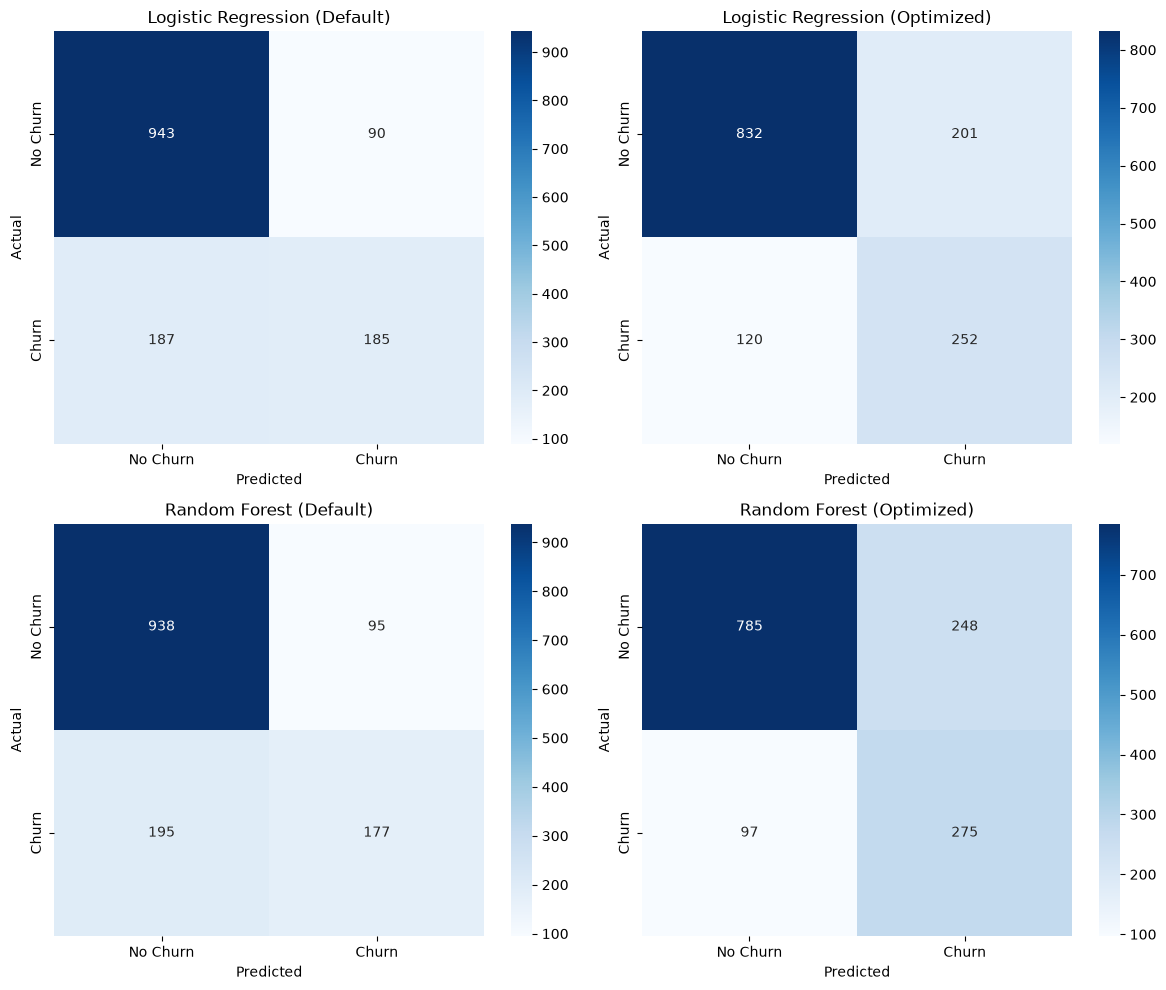

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(axes.flatten(), models.items()):

    cm = confusion_matrix(y_actual, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [20]:
for name, predictions in models.items():

    tn, fp, fn, tp = confusion_matrix(
        y_actual, predictions
    ).ravel()

    print(f"\n{name}")
    print("True Negatives :", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives :", tp)


Logistic Regression (Default)
True Negatives : 943
False Positives: 90
False Negatives: 187
True Positives : 185

Logistic Regression (Optimized)
True Negatives : 832
False Positives: 201
False Negatives: 120
True Positives : 252

Random Forest (Default)
True Negatives : 938
False Positives: 95
False Negatives: 195
True Positives : 177

Random Forest (Optimized)
True Negatives : 785
False Positives: 248
False Negatives: 97
True Positives : 275


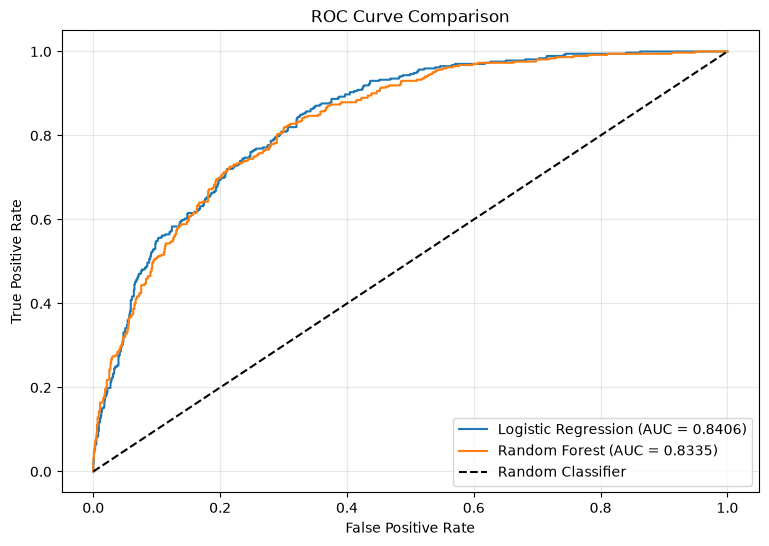

Logistic Regression AUC: 0.8406
Random Forest AUC: 0.8335


In [21]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_actual, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_actual, rf_probs)

# Calculate AUC
lr_auc = roc_auc_score(y_actual, lr_probs)
rf_auc = roc_auc_score(y_actual, rf_probs)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f'Logistic Regression (AUC = {lr_auc:.4f})'
)

plt.plot(
    rf_fpr, rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.4f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Logistic Regression AUC:", round(lr_auc, 4))
print("Random Forest AUC:", round(rf_auc, 4))

In [23]:
import pandas as pd
from sklearn.inspection import permutation_importance

# Calculate permutation importance
rf_permutation = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

# Create DataFrame
permutation_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': rf_permutation.importances_mean,
    'Std': rf_permutation.importances_std
})

# Sort features
permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print("Top 15 Permutation Important Features:")

display(permutation_importance_df.head(15))

Top 15 Permutation Important Features:


,Feature,Importance,Std
3,tenure,0.036207,0.004359
11,InternetService_Fiber optic,0.015882,0.003655
26,Contract_Two year,0.015454,0.003383
7,TotalCharges,0.013976,0.002381
25,Contract_One year,0.005498,0.001666
33,TenureGroup_Loyal,0.004678,0.001064
14,OnlineSecurity_Yes,0.003259,0.001388
20,TechSupport_Yes,0.001851,0.001208
28,PaymentMethod_Electronic check,0.001480,0.002438
5,PaperlessBilling,0.001190,0.001324


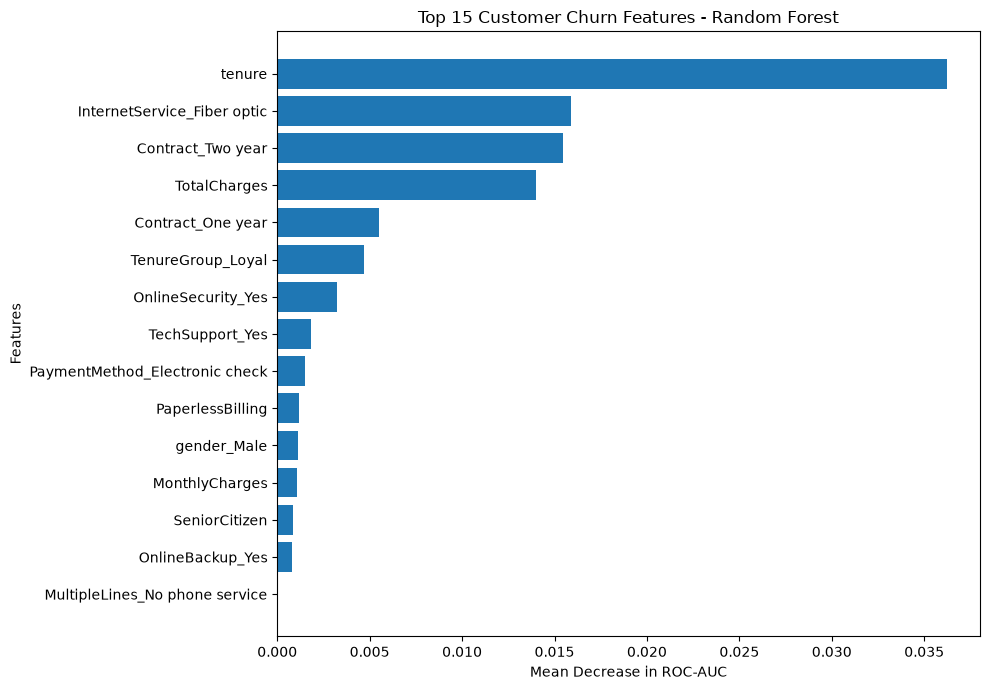

In [24]:
import matplotlib.pyplot as plt

top_features = permutation_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Features")
plt.title("Top 15 Customer Churn Features - Random Forest")

plt.tight_layout()
plt.show()

In [25]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance
rf_permutation = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

# Create feature importance table
permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_permutation.importances_mean,
    "Std": rf_permutation.importances_std
})

# Sort features
permutation_importance_df = (
    permutation_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display top 15
display(permutation_importance_df.head(15).round(5))

,Feature,Importance,Std
0,tenure,0.03621,0.00436
1,InternetService_Fiber optic,0.01588,0.00366
2,Contract_Two year,0.01545,0.00338
3,TotalCharges,0.01398,0.00238
4,Contract_One year,0.00550,0.00167
5,TenureGroup_Loyal,0.00468,0.00106
6,OnlineSecurity_Yes,0.00326,0.00139
7,TechSupport_Yes,0.00185,0.00121
8,PaymentMethod_Electronic check,0.00148,0.00244
9,PaperlessBilling,0.00119,0.00132


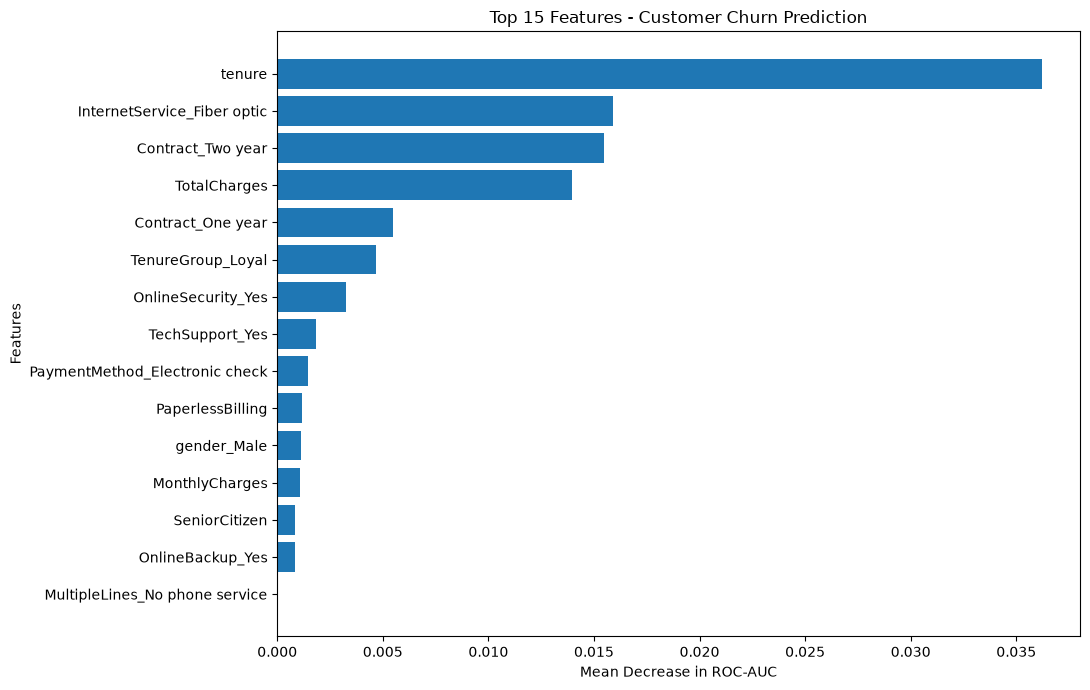

In [26]:
import matplotlib.pyplot as plt

top_features = permutation_importance_df.head(15)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Features")
plt.title("Top 15 Features - Customer Churn Prediction")

plt.tight_layout()
plt.savefig("../models/feature_importance.png", dpi=300)
plt.show()

In [27]:
# Save feature importance table
permutation_importance_df.to_csv(
    "../models/feature_importance.csv",
    index=False
)

print("Feature importance analysis completed!")
print("CSV and visualization saved successfully.")

Feature importance analysis completed!
CSV and visualization saved successfully.
